In [1]:
!pip -q install kagglehub
import kagglehub, os, glob, random, warnings
warnings.filterwarnings("ignore")
path = kagglehub.dataset_download("sovitrath/neu-steel-surface-defect-detect-trainvalid-split")
print("Dataset path:", path)

Using Colab cache for faster access to the 'neu-steel-surface-defect-detect-trainvalid-split' dataset.
Dataset path: /kaggle/input/neu-steel-surface-defect-detect-trainvalid-split


Images: 1800 | XML annotations: 1800
Counter({'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted_surface': 300, 'rolled-in_scale': 300, 'scratches': 300})


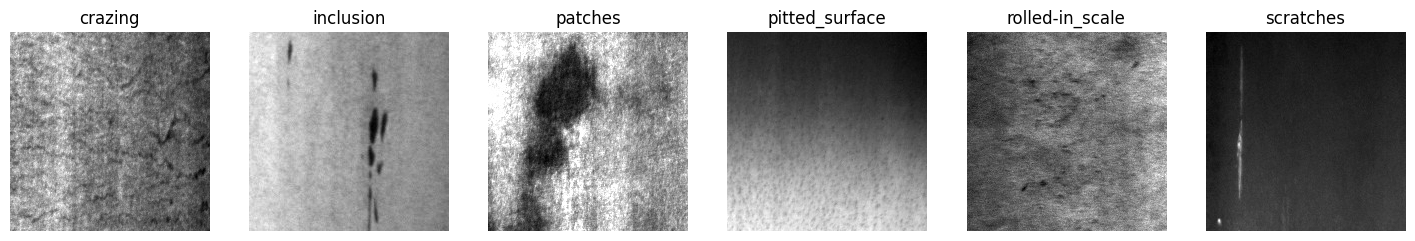

In [2]:
import numpy as np, cv2, matplotlib.pyplot as plt, xml.etree.ElementTree as ET
from collections import Counter

exts = ("jpg","jpeg","png","bmp")
imgs = sorted(p for e in exts for p in glob.glob(f"{path}/**/*.{e}", recursive=True))
xmls = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(f"{path}/**/*.xml", recursive=True)}
stem = lambda p: os.path.splitext(os.path.basename(p))[0]
cls_of = lambda p: stem(p).rsplit("_", 1)[0]

print("Images:", len(imgs), "| XML annotations:", len(xmls))
print(Counter(cls_of(p) for p in imgs))
classes = sorted(set(cls_of(p) for p in imgs))

fig, ax = plt.subplots(1, len(classes), figsize=(3*len(classes), 3))
for a, c in zip(np.atleast_1d(ax), classes):
    p = next(p for p in imgs if cls_of(p) == c)
    a.imshow(cv2.imread(p, 0), cmap="gray"); a.set_title(c); a.axis("off")
plt.show()

In [3]:
# NEU-DET has no "normal" images, so binary mode builds 100x100 patches from the XML boxes:
#   no overlap with any defect box -> class 0 (Non-Defective)
#   >=40% overlap with a defect box -> class 1 (Defective)
MODE = "binary"          # "binary" or "multiclass"
IMG  = 64 if MODE == "binary" else 128
P    = 100
rng  = np.random.default_rng(42)

def defect_mask(shape, xml_path):
    m = np.zeros(shape, np.uint8)
    for o in ET.parse(xml_path).getroot().iter("object"):
        b = o.find("bndbox")
        x1, y1, x2, y2 = [int(float(b.find(k).text)) for k in ("xmin","ymin","xmax","ymax")]
        m[y1:y2, x1:x2] = 1
    return m

def prep(g):  # grayscale image -> resize -> contrast equalisation
    g = cv2.resize(g, (IMG, IMG), interpolation=cv2.INTER_AREA)
    return cv2.equalizeHist(g)

X, y, groups = [], [], []
for gi, p in enumerate(imgs):
    g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if g is None: continue
    if MODE == "multiclass":
        X.append(prep(g)); y.append(classes.index(cls_of(p))); groups.append(gi)
    else:
        if stem(p) not in xmls: continue
        m = defect_mask(g.shape, xmls[stem(p)]); h, w = g.shape
        if h < P or w < P: continue
        normals, defects = [], []
        for _ in range(40):
            x0, y0 = rng.integers(0, w-P+1), rng.integers(0, h-P+1)
            f = m[y0:y0+P, x0:x0+P].mean()
            if f == 0: normals.append((x0, y0))
            elif f >= 0.4: defects.append((x0, y0))
        for lst, lab in ((normals[:2], 0), (defects[:2], 1)):
            for x0, y0 in lst:
                X.append(prep(g[y0:y0+P, x0:x0+P])); y.append(lab); groups.append(gi)

X, y, groups = np.array(X), np.array(y), np.array(groups)

if MODE == "binary":   # balance classes
    n = min((y==0).sum(), (y==1).sum())
    keep = np.concatenate([rng.choice(np.where(y==k)[0], n, replace=False) for k in (0,1)])
    X, y, groups = X[keep], y[keep], groups[keep]
    names = ["Non-Defective", "Defective"]
else:
    names = classes
print("Dataset:", X.shape, Counter(y.tolist()))

# Split by SOURCE IMAGE (no leakage): 70% train / 15% val / 15% test
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(1, test_size=0.15, random_state=0)
tv, te = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(1, test_size=0.15/0.85, random_state=0)
tr, va = next(gss2.split(X[tv], y[tv], groups[tv])); tr, va = tv[tr], tv[va]
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
print("train/val/test:", len(tr), len(va), len(te))
AVG = "binary" if MODE == "binary" else "macro"

Dataset: (1672, 64, 64) Counter({0: 836, 1: 836})
train/val/test: 1157 253 262


Feature length (8x8 cells, 9 orient.): 1764


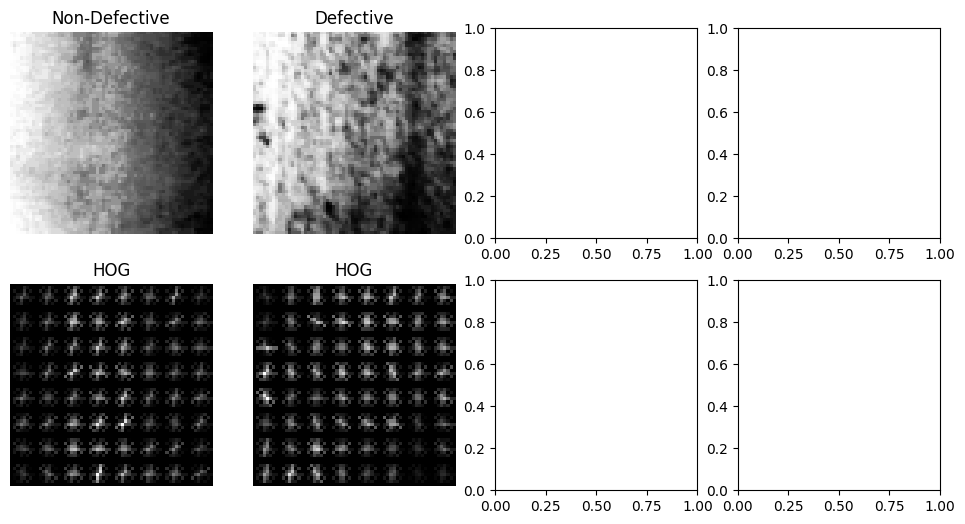

In [4]:
from skimage.feature import hog

def hog_feat(im, ppc=8, ori=9):
    return hog(im, orientations=ori, pixels_per_cell=(ppc, ppc),
               cells_per_block=(2, 2), block_norm="L2-Hys")

def extract(images, ppc=8, ori=9):
    return np.array([hog_feat(i, ppc, ori) for i in images])

print("Feature length (8x8 cells, 9 orient.):", len(hog_feat(X[0])))

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
shown = []
for k in np.unique(y)[:4]:
    i = np.where(y == k)[0][0]
    _, hi = hog(X[i], orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), visualize=True)
    j = len(shown); shown.append(k)
    ax[0, j].imshow(X[i], cmap="gray"); ax[0, j].set_title(names[k]); ax[0, j].axis("off")
    ax[1, j].imshow(hi, cmap="gray");   ax[1, j].set_title("HOG");      ax[1, j].axis("off")
plt.show()


===== HOG + SVM =====
{'Acc': 0.7099, 'Prec': 0.6614, 'Rec': 0.7179, 'F1': 0.6885}
               precision    recall  f1-score   support

Non-Defective       0.76      0.70      0.73       145
    Defective       0.66      0.72      0.69       117

     accuracy                           0.71       262
    macro avg       0.71      0.71      0.71       262
 weighted avg       0.71      0.71      0.71       262



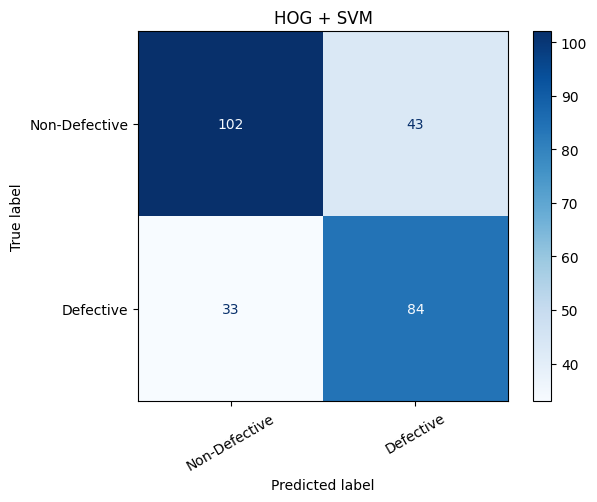


===== HOG + RandomForest =====
{'Acc': 0.7366, 'Prec': 0.6846, 'Rec': 0.7607, 'F1': 0.7206}
               precision    recall  f1-score   support

Non-Defective       0.79      0.72      0.75       145
    Defective       0.68      0.76      0.72       117

     accuracy                           0.74       262
    macro avg       0.74      0.74      0.74       262
 weighted avg       0.74      0.74      0.74       262



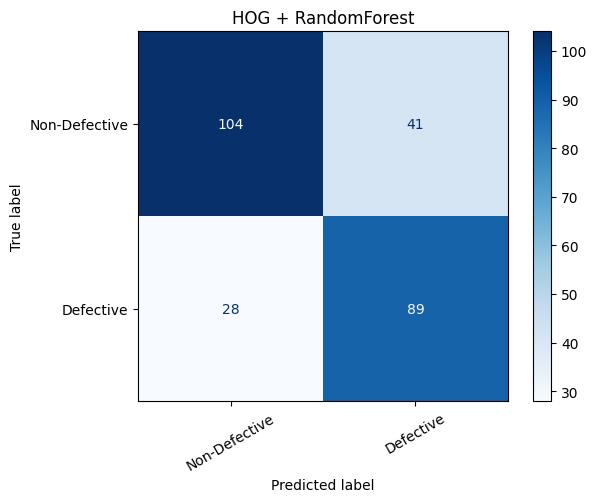

In [5]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

def make_clf(kind):
    if kind == "SVM":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", probability=True))
    return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)

def metrics(yt, yp):
    return dict(Acc=accuracy_score(yt, yp),
                Prec=precision_score(yt, yp, average=AVG, zero_division=0),
                Rec=recall_score(yt, yp, average=AVG, zero_division=0),
                F1=f1_score(yt, yp, average=AVG, zero_division=0))

Ftr, Fte = extract(Xtr), extract(Xte)
models = {}
for kind in ("SVM", "RandomForest"):
    models[kind] = make_clf(kind).fit(Ftr, ytr)
    yp = models[kind].predict(Fte)
    print(f"\n===== HOG + {kind} =====")
    print({k: round(v, 4) for k, v in metrics(yte, yp).items()})
    print(classification_report(yte, yp, target_names=names, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(yte, yp), display_labels=names).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"HOG + {kind}"); plt.show()

In [6]:
import pandas as pd, time
rows = []
for ppc in (4, 8, 16):
    for ori in (6, 9, 12):
        t = time.time()
        A, B, C = extract(Xtr, ppc, ori), extract(Xva, ppc, ori), extract(Xte, ppc, ori)
        for kind in ("SVM", "RandomForest"):
            m = make_clf(kind).fit(A, ytr)
            v = metrics(yva, m.predict(B)); s = metrics(yte, m.predict(C))
            rows.append(dict(Cell=f"{ppc}x{ppc}", Orient=ori, Model=kind, Features=A.shape[1],
                             Val_F1=round(v["F1"],4), Test_Acc=round(s["Acc"],4), Test_F1=round(s["F1"],4)))
        print(f"cell {ppc}, ori {ori} done ({time.time()-t:.0f}s)")
results = pd.DataFrame(rows)
display(results)
print(results.pivot_table(index="Cell", columns=["Model","Orient"], values="Test_F1"))

best = results.sort_values("Val_F1", ascending=False).iloc[0]     # chosen by VALIDATION F1
BEST_PPC, BEST_ORI, BEST_MODEL = int(best.Cell.split("x")[0]), int(best.Orient), best.Model
print("\nBest config ->", BEST_MODEL, "cell", BEST_PPC, "orient", BEST_ORI)

cell 4, ori 6 done (44s)
cell 4, ori 9 done (65s)
cell 4, ori 12 done (94s)
cell 8, ori 6 done (12s)
cell 8, ori 9 done (16s)
cell 8, ori 12 done (18s)
cell 16, ori 6 done (6s)
cell 16, ori 9 done (5s)
cell 16, ori 12 done (7s)


,Cell,Orient,Model,Features,Val_F1,Test_Acc,Test_F1
0,4x4,6,SVM,5400,0.7857,0.7519,0.7325
1,4x4,6,RandomForest,5400,0.7226,0.7252,0.7049
2,4x4,9,SVM,8100,0.7407,0.7634,0.7395
3,4x4,9,RandomForest,8100,0.7324,0.7366,0.7229
4,4x4,12,SVM,10800,0.7805,0.7481,0.7381
5,4x4,12,RandomForest,10800,0.7465,0.7099,0.7008
6,8x8,6,SVM,1176,0.7872,0.7328,0.7107
7,8x8,6,RandomForest,1176,0.7596,0.7519,0.7431
8,8x8,9,SVM,1764,0.7562,0.7099,0.6885
9,8x8,9,RandomForest,1764,0.6866,0.7366,0.7206


Model  RandomForest                     SVM                
Orient           6       9       12      6       9       12
Cell                                                       
16x16        0.7419  0.7470  0.7529  0.7120  0.7510  0.7742
4x4          0.7049  0.7229  0.7008  0.7325  0.7395  0.7381
8x8          0.7431  0.7206  0.7717  0.7107  0.6885  0.7398

Best config -> SVM cell 8 orient 6


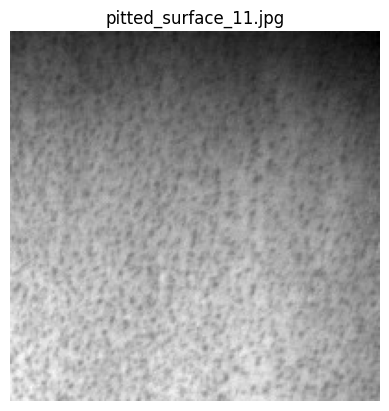

NameError: name 'final' is not defined

In [7]:
def inspect_product(img_gray, reject_threshold=0.5):
    # binary mode: scan with 100x100 windows (stride 50); reject if ANY window looks defective
    if MODE == "binary":
        h, w = img_gray.shape
        pats = [prep(img_gray[y0:y0+P, x0:x0+P]) for y0 in range(0, max(h-P,0)+1, 50)
                                                 for x0 in range(0, max(w-P,0)+1, 50)]
        pdef = final.predict_proba(extract(np.array(pats), BEST_PPC, BEST_ORI))[:, 1].max()
        defective, conf = pdef >= reject_threshold, (pdef if pdef >= reject_threshold else 1 - pdef)
        label = "DEFECTIVE" if defective else "NON-DEFECTIVE"
    else:
        pr = final.predict_proba(extract(prep(img_gray)[None], BEST_PPC, BEST_ORI))[0]
        k = int(pr.argmax()); defective, conf = True, pr[k]; label = f"DEFECTIVE ({names[k]})"
    print("PRODUCT INSPECTION RESULT")
    print(f"Prediction: {label}")
    print(f"Confidence: {conf*100:.1f}%")
    print("Action:", "REJECT PRODUCT" if defective else "ACCEPT PRODUCT")
    return defective

# demo on 3 random dataset images
for p in random.sample(imgs, 3):
    g = cv2.imread(p, 0); plt.imshow(g, cmap="gray"); plt.title(os.path.basename(p)); plt.axis("off"); plt.show()
    inspect_product(g); print("-"*40)